<a href="https://colab.research.google.com/github/hamagami/IS2026/blob/main/Demo12_Attention_Context.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Demo 12 — Attention Weights Change with Context / 文脈で変わるAttention Weight

**Intelligent Systems — Attention & Transformer**

**Goal / 目的:** Understand the steps **Q × K → Softmax → Weighted Sum of V**, then visualize how the same target word changes what it attends to when the **context changes**.  
「QueryとKeyで重みを計算し、Valueを集約する」仕組みを**見える形**で学びます。

The first section is a **transparent teaching model with intentionally designed vectors** (not a pretrained language model). The final optional section visualizes a **real pretrained Transformer**.  
前半は原理を理解するための手設計の小さなモデルです（実際のBERTが学習した重みではありません）。後半に事前学習済みモデルの発展編を用意します。

> Colab: **Runtime → Run all / ランタイム → すべてのセルを実行**. The basic demo works on CPU without a network model download.


In [ ]:
%pip -q install numpy matplotlib ipywidgets


## A. Intuition / 直感

- **Query (Q):** What information is this token looking for? / 求める情報
- **Key (K):** What can this token match against? / 照合する特徴
- **Value (V):** What information does this token contribute? / 集約する情報

For a selected query token \(i\), attention is:

\[
 s_{ij}=rac{q_i\cdot k_j}{\sqrt{d_k}}, \qquad
 lpha_{ij}=rac{e^{s_{ij}}}{\sum_t e^{s_{it}}}, \qquad
 z_i=\sum_j lpha_{ij}v_j.
\]

We use small 2D Q, K, V vectors so every step can be inspected. / 計算を追えるように2次元ベクトルを使用します。


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import ipywidgets as widgets
from IPython.display import display, clear_output

SCENES={
 'River / 川岸': ['The','bank','is','beside','the','river'],
 'Finance / 銀行': ['She','deposited','money','at','the','bank'],
 'River + nature / 川岸（別文）': ['We','sat','on','the','bank','near','water'],
 'Finance + cash / 銀行（別文）': ['The','bank','approved','my','loan']
}
# Keys: a small hand-designed semantic feature space / 手設計の意味特徴空間
# dimension 0 = nature (自然), dimension 1 = finance (金融)
K_LOOKUP={'river':[3.0,0.0],'water':[2.7,0.0],'beside':[0.6,0.0],
          'money':[0.0,3.0],'deposited':[0.0,2.3],'loan':[0.0,3.0],'approved':[0.0,1.9],
          'bank':[0.2,0.2]}
# Values carry interpretable evidence / Vは取り込む情報（説明用）
V_LOOKUP={'river':[1.0,0.0],'water':[1.0,0.0],'beside':[0.25,0.0],
          'money':[0.0,1.0],'deposited':[0.0,0.8],'loan':[0.0,1.0],'approved':[0.0,0.6],
          'bank':[0.1,0.1]}

def softmax(x):
    z=np.asarray(x)-np.max(x);e=np.exp(z);return e/e.sum()

def build_scene(scene, query='bank',temperature=1.0):
    tokens=SCENES[scene];qidx=tokens.index(query)
    K=np.array([K_LOOKUP.get(w.lower(),[0,0]) for w in tokens],float)
    V=np.array([V_LOOKUP.get(w.lower(),[0,0]) for w in tokens],float)
    Q=np.array([1.0,1.0]) # query of bank searches for semantic evidence in either direction
    scores=(K@Q)/(np.sqrt(2)*temperature);weights=softmax(scores)
    contributions=weights[:,None]*V;output=contributions.sum(axis=0)
    return dict(tokens=tokens,qidx=qidx,Q=Q,K=K,V=V,scores=scores,weights=weights,contributions=contributions,output=output)

def draw_scene(scene='River / 川岸',temperature=1.0,show_vectors=True):
    r=build_scene(scene,temperature=temperature);words=r['tokens'];w=r['weights'];n=len(words);qi=r['qidx']
    fig=plt.figure(figsize=(14,7 if show_vectors else 5))
    gs=fig.add_gridspec(2 if show_vectors else 1,2,width_ratios=[1.2,1],height_ratios=([1.05,1] if show_vectors else [1]))
    ax=fig.add_subplot(gs[0,0]);ax.set_xlim(-.7,n-.3);ax.set_ylim(-.15,1.25);ax.axis('off')
    for j,word in enumerate(words):
        col='#e2c8fa' if j==qi else '#dbeafe'
        ax.text(j,0,word,ha='center',va='center',fontsize=12,bbox={'boxstyle':'round,pad=.35','fc':col,'ec':'#7995c0'})
        if j!=qi:
            arrow=FancyArrowPatch((qi,.15),(j,.15),connectionstyle=f'arc3,rad={-.28 if j>qi else .28}',
                                  arrowstyle='-|>',mutation_scale=12,color='#7446b4',
                                  linewidth=.7+7*w[j],alpha=.28+.68*w[j]/max(w))
            ax.add_patch(arrow)
        ax.text(j,-.12,f'{w[j]:.2f}',ha='center',fontsize=9)
    ax.set_title(f'{scene} — Query = "bank" / 線の太さ = Attention Weight',fontsize=12)
    ax2=fig.add_subplot(gs[0,1]);colors=['#8555c6' if i==np.argmax(w) else '#79afd6' for i in range(n)]
    ax2.bar(np.arange(n),w,color=colors);ax2.set_xticks(np.arange(n),words,rotation=35,ha='right');ax2.set_ylim(0,max(.75,w.max()*1.13))
    for j,val in enumerate(w):ax2.text(j,val+.015,f'{val:.2f}',ha='center',fontsize=9)
    ax2.set_ylabel('Attention weight');ax2.set_title('Softmax(Q · K / √dₖ)')
    if show_vectors:
        ax3=fig.add_subplot(gs[1,0]);im=ax3.imshow(w[None,:],cmap='Purples',vmin=0,vmax=1,aspect='auto')
        ax3.set_xticks(np.arange(n),words,rotation=30,ha='right');ax3.set_yticks([0],['bank →']);ax3.set_title('One query row / Attention行列の1行')
        for j,val in enumerate(w):ax3.text(j,0,f'{val:.2f}',ha='center',va='center',color='black',fontsize=10)
        ax4=fig.add_subplot(gs[1,1]);c=r['contributions']
        ax4.bar(np.arange(n)-.18,c[:,0],.36,label='Nature / 自然');ax4.bar(np.arange(n)+.18,c[:,1],.36,label='Finance / 金融')
        ax4.set_xticks(np.arange(n),words,rotation=35,ha='right');ax4.set_title('Weighted Values (α × V) / 情報の寄与');ax4.legend(fontsize=8)
    fig.tight_layout();plt.show()
    print('Query Q / 問い合わせ:',r['Q'])
    print('Output z = Σ α V / 集約結果:',np.round(r['output'],3),'[nature, finance]')
    print('High weight means more contribution to the weighted sum (not necessarily a human explanation of meaning).')
    print('重みはVの集約量を決めますが、人間の意味解釈そのものを保証しません。')
    return r


## B. Interactive visual / 文脈を切り替えて可視化

同じ `bank` に注目したまま文脈を切り替え、`river` と `money` などのAttention Weightを比較します。  
Keep **bank** as the query token and switch the surrounding words. Adjust temperature to see the effect on Softmax sharpness.


In [ ]:
scene_w=widgets.Dropdown(options=list(SCENES),value='River / 川岸',description='Context')
temp_w=widgets.FloatSlider(value=1.0,min=0.4,max=3.0,step=0.2,description='Temperature')
vectors_w=widgets.Checkbox(value=True,description='Show Q/K/V contribution / 詳細表示')
plot_out=widgets.Output()

def redraw(_=None):
    with plot_out:
        clear_output(wait=True)
        draw_scene(scene_w.value,temp_w.value,vectors_w.value)
for w in [scene_w,temp_w,vectors_w]:w.observe(redraw,names='value')
display(widgets.VBox([widgets.HBox([scene_w,temp_w]),vectors_w,plot_out]))
redraw()


## C. Inspect the numbers / Q, K, V の計算を確認

Switch the context above, then rerun this cell. / 上の文脈を変えたあと、このセルを再実行してください。


In [ ]:
r=build_scene(scene_w.value,temperature=temp_w.value)
print(f'Context / 文脈: {scene_w.value}')
print('Query Q / bankのQ:',r['Q'])
print(' token / 単語    key K         score       softmax α     value V       α×V')
for i,word in enumerate(r['tokens']):
    print(f'{word:>10s}   {str(r["K"][i]):16s}  {r["scores"][i]:6.2f}       {r["weights"][i]:6.3f}       {str(r["V"][i]):16s} {np.round(r["contributions"][i],3)}')
print('Sum of α / 重みの合計:',round(float(r['weights'].sum()),6))
print('Sum(α V) / 出力:',np.round(r['output'],4))


Context / 文脈: River / 川岸
Query Q / bankのQ: [1. 1.]
 token / 単語    key K         score       softmax α     value V       α×V
       The   [0. 0.]             0.00        0.070       [0. 0.]          [0. 0.]
      bank   [0.2 0.2]           0.28        0.093       [0.1 0.1]        [0.009 0.009]
        is   [0. 0.]             0.00        0.070       [0. 0.]          [0. 0.]
    beside   [0.6 0. ]           0.42        0.108       [0.25 0.  ]      [0.027 0.   ]
       the   [0. 0.]             0.00        0.070       [0. 0.]          [0. 0.]
     river   [3. 0.]             2.12        0.588       [1. 0.]          [0.588 0.   ]
Sum of α / 重みの合計: 1.0
Sum(α V) / 出力: [0.6238 0.0093]


## D. Compare two contexts side by side / 2つの文脈を同時に比較

This comparison uses the **same Q, same K/V lookup, and same Softmax**; only the input words differ.  
Qと計算規則は固定したまま、入力の単語だけを変えます。


/tmp/ipykernel_868/1320608741.py:6: UserWarning: Glyph 24029 (\N{CJK UNIFIED IDEOGRAPH-5DDD}) missing from font(s) DejaVu Sans.
  axs[0].set_ylabel('Attention weight');fig.suptitle('Same query "bank", different contexts / 同じbankでも重視する情報は変わる');fig.tight_layout();plt.show()
/tmp/ipykernel_868/1320608741.py:6: UserWarning: Glyph 23736 (\N{CJK UNIFIED IDEOGRAPH-5CB8}) missing from font(s) DejaVu Sans.
  axs[0].set_ylabel('Attention weight');fig.suptitle('Same query "bank", different contexts / 同じbankでも重視する情報は変わる');fig.tight_layout();plt.show()
/tmp/ipykernel_868/1320608741.py:6: UserWarning: Glyph 37504 (\N{CJK UNIFIED IDEOGRAPH-9280}) missing from font(s) DejaVu Sans.
  axs[0].set_ylabel('Attention weight');fig.suptitle('Same query "bank", different contexts / 同じbankでも重視する情報は変わる');fig.tight_layout();plt.show()
/tmp/ipykernel_868/1320608741.py:6: UserWarning: Glyph 34892 (\N{CJK UNIFIED IDEOGRAPH-884C}) missing from font(s) DejaVu Sans.
  axs[0].set_ylabel('Attention weight');fig.suptitle(

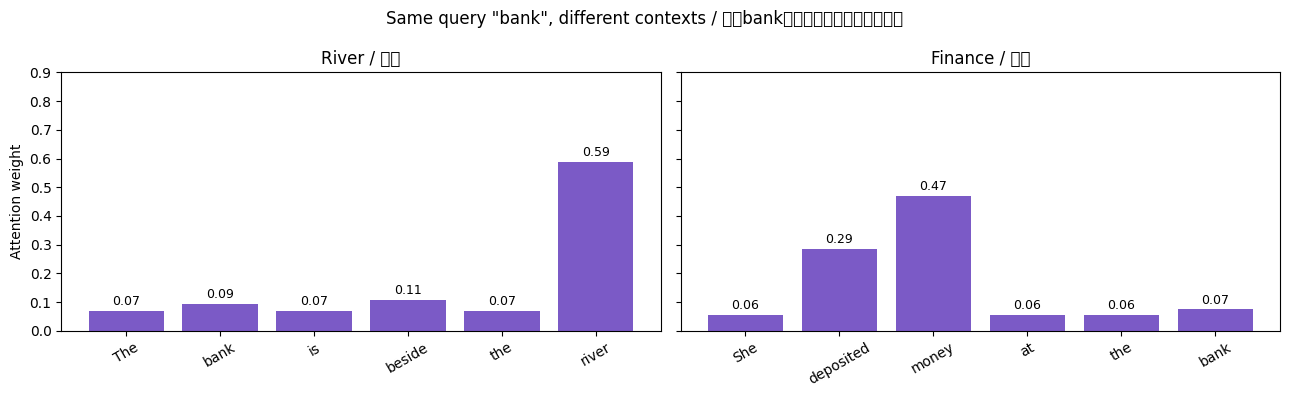

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,scene in zip(axs,['River / 川岸','Finance / 銀行']):
    r=build_scene(scene);ax.bar(r['tokens'],r['weights'],color='#7b5ac6');ax.set_title(scene);ax.set_ylim(0,.9)
    ax.tick_params(axis='x',labelrotation=30)
    for i,v in enumerate(r['weights']): ax.text(i,v+.02,f'{v:.2f}',ha='center',fontsize=9)
axs[0].set_ylabel('Attention weight');fig.suptitle('Same query "bank", different contexts / 同じbankでも重視する情報は変わる');fig.tight_layout();plt.show()


## E. Optional advanced demo — Real pretrained BERT / 発展編：実際のBERT（任意）

**Important / 重要:** The engineered examples above intentionally show the principle; a pretrained BERT can display different or less human-interpretable patterns.  
こちらは実際のモデルのAttentionです。`river`に必ず高い重みが付くわけではありません。重みは意味の説明と同一ではありません。

Run the next two cells only if Colab internet access is available to download a model (~hundreds of MB). / モデル取得にはインターネットが必要です。不要ならスキップできます。


In [ ]:
# Optional dependency / 任意（BERT）
%pip -q install transformers


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


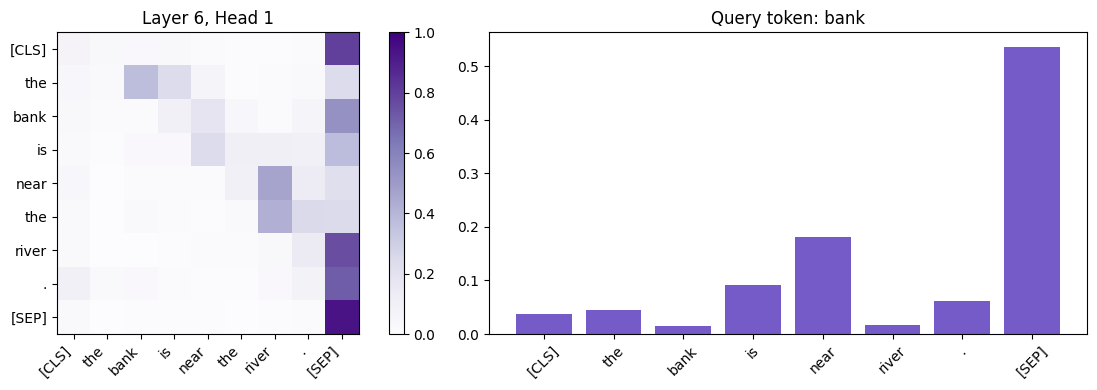

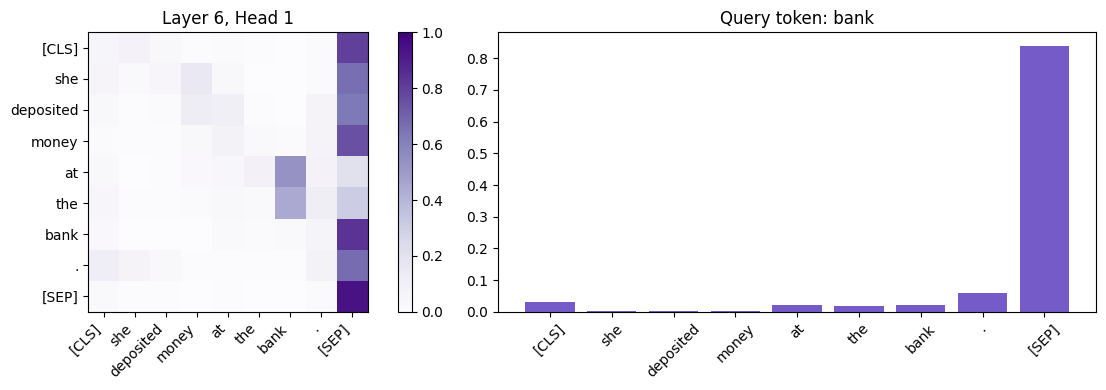

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModel
name='bert-base-uncased'
tokenizer=AutoTokenizer.from_pretrained(name)
model=AutoModel.from_pretrained(name,attn_implementation='eager',output_attentions=True)
model.eval()

def show_bert_attention(sentence='The bank is near the river.',layer=5,head=0,focus='bank'):
    tokens=tokenizer(sentence,return_tensors='pt')
    with torch.no_grad(): result=model(**tokens)
    t=tokenizer.convert_ids_to_tokens(tokens['input_ids'][0])
    A=result.attentions[layer][0,head].cpu().numpy()
    idx=t.index(focus) if focus in t else 1
    fig,ax=plt.subplots(1,2,figsize=(13,4))
    im=ax[0].imshow(A,vmin=0,vmax=1,cmap='Purples')
    ax[0].set_xticks(range(len(t)),t,rotation=45,ha='right');ax[0].set_yticks(range(len(t)),t);ax[0].set_title(f'Layer {layer+1}, Head {head+1}')
    fig.colorbar(im,ax=ax[0],fraction=.045)
    ax[1].bar(t,A[idx],color='#745bc8');ax[1].tick_params(axis='x',labelrotation=45);ax[1].set_title(f'Query token: {t[idx]}')
    fig.tight_layout();plt.show()

show_bert_attention('The bank is near the river.',layer=5,head=0)
show_bert_attention('She deposited money at the bank.',layer=5,head=0)


## Questions for students / 考察課題

1. **Context / 文脈:** Why does `bank` attend to different words in the two sentences? / なぜbankのAttention Weightが変わるか。
2. **Softmax / 正規化:** Increase temperature. Does attention become more uniform? / 温度を上げると重みはどう変わるか。
3. **Value / 集約:** Which semantic dimension contributes more to the output, nature or finance? / 出力に寄与するのはどの特徴か。
4. **BERT / 実モデル:** Do all heads focus on the same word? / 複数のHeadは同じ場所を見るか。
5. **Interpretation / 注意:** Can a high attention weight alone prove a word's semantic role? **No.** / Attention Weightだけで人間的な意味を断定できるか（できない）。

**Takeaway / まとめ:** The **parameters used to compute** Q/K/V can remain fixed at inference, while **attention weights vary with the input**.  
Q/K/Vを求めるパラメータが固定されていても、入力が違えばAttention Weightは変化します。
